# TASK-016 — Prompting Strategy Comparison

Compare basic and advanced Qwen3-4B prompts using two reproducible, class-balanced sets of 800 existing generated AG News articles. Check generation settings, quality, diversity, and the separate 40-item human realism review.

In [1]:
from pathlib import Path
import hashlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd() / "data" / "synthetic" / "full_unfiltered.csv").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.filter_data import _embed, distinct_2, normalize, words

DATA = ROOT / "data" / "synthetic"
SOURCE = pd.read_csv(DATA / "full_unfiltered.csv")
FILTERED_IDS = set(pd.read_csv(DATA / "full_filtered.csv", usecols=["sample_id"]).sample_id)
REVIEW = pd.read_csv(ROOT / "results" / "task006" / "review_scored.csv")
CATEGORIES = ["World", "Sports", "Business", "Sci/Tech"]
SETTINGS = ["model", "model_digest", "temperature", "top_p", "top_k", "num_predict", "system_prompt_sha256"]

assert len(SOURCE) == 8_000 and SOURCE.sample_id.is_unique
assert set(SOURCE.strategy) == {"basic", "advanced"}
assert SOURCE[SETTINGS].drop_duplicates().shape[0] == 1
for strategy in ("basic", "advanced"):
    expected = hashlib.sha256((ROOT / "prompts" / f"{strategy}.txt").read_bytes()).hexdigest()
    assert SOURCE.loc[SOURCE.strategy.eq(strategy), "prompt_sha256"].eq(expected).all()
assert all(SOURCE.loc[SOURCE.label.eq(label), "category"].eq(category).all()
           for label, category in enumerate(CATEGORIES))
display(SOURCE.groupby(["strategy", "category"]).size().unstack(fill_value=0).reindex(columns=CATEGORIES))
display(SOURCE[SETTINGS].drop_duplicates())

category,World,Sports,Business,Sci/Tech
strategy,,,,
advanced,1800,1800,1800,1800
basic,200,200,200,200


,model,model_digest,temperature,top_p,top_k,num_predict,system_prompt_sha256
0,qwen3:4b-instruct,0edcdef34593eac1aa2be9c7d06c432dcf81945adca5ec...,0.85,0.8,20,180,7238dd806f8ac3c7fcc6b9ca60f20fae7c890433c67de7...


In [2]:
basic = SOURCE[SOURCE.strategy.eq("basic")].copy()
advanced = (SOURCE[SOURCE.strategy.eq("advanced")]
            .groupby("category", group_keys=False)
            .sample(n=200, random_state=16)
            .sort_values(["label", "sample_id"]).copy())
sets = {"basic": basic, "advanced": advanced}
for strategy, frame in sets.items():
    assert len(frame) == 800 and frame.sample_id.is_unique
    assert frame.category.value_counts().to_dict() == {category: 200 for category in CATEGORIES}
    assert frame[SETTINGS].drop_duplicates().shape[0] == 1
    assert frame[["text", "headline", "summary"]].notna().all().all()
    assert frame.text.map(normalize).is_unique
    frame.to_csv(DATA / f"prompt_{strategy}_800.csv", index=False)

assert not set(basic.sample_id) & set(advanced.sample_id)
print("Saved:", DATA / "prompt_basic_800.csv", "and", DATA / "prompt_advanced_800.csv")
display(pd.DataFrame({strategy: frame.category.value_counts().reindex(CATEGORIES)
                      for strategy, frame in sets.items()}))

Saved: D:\Projects\5_sem\Natural Language Processing\lab4\Synthetic-Data-NLP_Lab-4_3rd-course-\data\synthetic\prompt_basic_800.csv and D:\Projects\5_sem\Natural Language Processing\lab4\Synthetic-Data-NLP_Lab-4_3rd-course-\data\synthetic\prompt_advanced_800.csv


,basic,advanced
category,,
World,200,200
Sports,200,200
Business,200,200
Sci/Tech,200,200


In [3]:
def distinct_n_first35(texts, n):
    grams = [tuple(tokens[i:i+n])
             for text in texts
             for tokens in [words(text)[:35]]
             for i in range(len(tokens) - n + 1)]
    return len(set(grams)) / len(grams) if grams else np.nan

quality_rows = []
for strategy, frame in sets.items():
    for category in CATEGORIES:
        group = frame[frame.category.eq(category)]
        lengths = group.text.map(lambda text: len(words(text)))
        quality_rows.append({
            "strategy": strategy, "category": category, "articles": len(group),
            "mean_words": lengths.mean(), "median_words": lengths.median(),
            "outside_35_80": int((~lengths.between(35, 80)).sum()),
            "filter_retained": int(group.sample_id.isin(FILTERED_IDS).sum()),
            "filter_retention_pct": 100 * group.sample_id.isin(FILTERED_IDS).mean(),
            "distinct_1_first35": distinct_n_first35(group.text, 1),
            "distinct_2_first35": distinct_n_first35(group.text, 2),
            "distinct_2_all": distinct_2(group.text.tolist()),
        })
quality = pd.DataFrame(quality_rows)
display(quality.round(3))
assert all(frame.text.map(normalize).is_unique for frame in sets.values())

,strategy,category,articles,mean_words,median_words,outside_35_80,filter_retained,filter_retention_pct,distinct_1_first35,distinct_2_first35,distinct_2_all
0,basic,World,200,57.095,57.0,0,153,76.5,0.137,0.420,0.420
1,basic,Sports,200,56.585,56.0,0,115,57.5,0.068,0.182,0.182
2,basic,Business,200,56.980,57.0,0,109,54.5,0.080,0.243,0.243
3,basic,Sci/Tech,200,58.100,58.0,0,153,76.5,0.080,0.225,0.225
4,advanced,World,200,68.760,69.0,0,186,93.0,0.205,0.662,0.662
5,advanced,Sports,200,69.915,70.0,0,194,97.0,0.218,0.659,0.659
6,advanced,Business,200,67.490,67.5,0,200,100.0,0.205,0.650,0.650
7,advanced,Sci/Tech,200,70.745,71.0,0,191,95.5,0.194,0.602,0.602


In [4]:
# Compare semantic diversity within each category, so topic labels do not dominate similarity.
combined = pd.concat([basic, advanced], ignore_index=True)
with requests.Session() as session:
    vectors = _embed(session, combined.text.tolist())

semantic_rows = []
for strategy, frame in sets.items():
    for category in CATEGORIES:
        positions = combined.index[(combined.strategy.eq(strategy) & combined.category.eq(category))].to_numpy()
        similarities = vectors[positions] @ vectors[positions].T
        pairs = similarities[np.triu_indices(len(positions), k=1)]
        semantic_rows.append({
            "strategy": strategy, "category": category,
            "mean_pairwise_cosine": float(pairs.mean()),
            "semantic_diversity": float(1 - pairs.mean()),
            "pairs_cosine_ge_0_90": int((pairs >= 0.90).sum()),
        })
semantic = pd.DataFrame(semantic_rows)
display(semantic.round(3))

,strategy,category,mean_pairwise_cosine,semantic_diversity,pairs_cosine_ge_0_90
0,basic,World,0.340,0.660,162
1,basic,Sports,0.498,0.502,1556
2,basic,Business,0.543,0.457,1023
3,basic,Sci/Tech,0.559,0.441,510
4,advanced,World,0.213,0.787,0
5,advanced,Sports,0.240,0.760,0
6,advanced,Business,0.227,0.773,0
7,advanced,Sci/Tech,0.235,0.765,0


category_fit_1to5             realism_1to5            
                      mean   std count         mean   std count
strategy                                                       
advanced              5.00  0.00    20          2.9  1.17    20
basic                 4.95  0.22    20          3.0  0.92    20

strategy,advanced,basic
category,,
World,2.2,3.4
Sports,2.2,2.2
Business,3.6,3.2
Sci/Tech,3.6,3.2


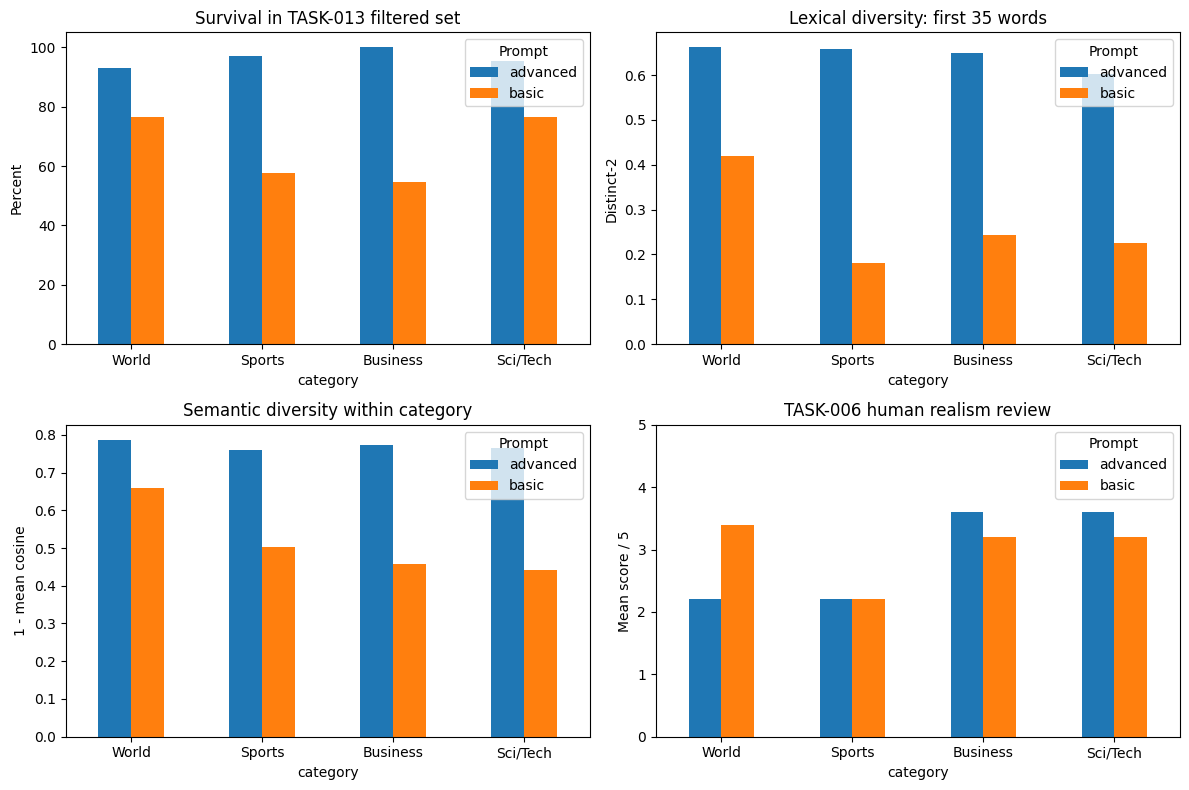

In [5]:
assert len(REVIEW) == 40 and REVIEW.groupby(["strategy", "category"]).size().eq(5).all()
review_summary = REVIEW.groupby("strategy")[["category_fit_1to5", "realism_1to5"]].agg(["mean", "std", "count"])
display(review_summary.round(2))
display(REVIEW.pivot_table(index="category", columns="strategy", values="realism_1to5").reindex(CATEGORIES).round(2))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
quality.pivot(index="category", columns="strategy", values="filter_retention_pct").reindex(CATEGORIES).plot.bar(ax=axes[0, 0], rot=0)
axes[0, 0].set(title="Survival in TASK-013 filtered set", ylabel="Percent")
quality.pivot(index="category", columns="strategy", values="distinct_2_first35").reindex(CATEGORIES).plot.bar(ax=axes[0, 1], rot=0)
axes[0, 1].set(title="Lexical diversity: first 35 words", ylabel="Distinct-2")
semantic.pivot(index="category", columns="strategy", values="semantic_diversity").reindex(CATEGORIES).plot.bar(ax=axes[1, 0], rot=0)
axes[1, 0].set(title="Semantic diversity within category", ylabel="1 - mean cosine")
REVIEW.pivot_table(index="category", columns="strategy", values="realism_1to5").reindex(CATEGORIES).plot.bar(ax=axes[1, 1], rot=0)
axes[1, 1].set(title="TASK-006 human realism review", ylabel="Mean score / 5", ylim=(0, 5))
for ax in axes.flat:
    ax.legend(title="Prompt")
fig.tight_layout()
plt.show()

TASK-013 retention combines automatic filtering with limited manual and rule-based exclusions. It depends on the full 8,000-item pool and is only a quality-screening proxy. Realism scores come from a separate 40-item TASK-006 pilot (20 per strategy); they do not validate every saved article.

In [6]:
examples = pd.concat([
    REVIEW[REVIEW.strategy.eq(strategy)].sort_values(["realism_1to5", "sample_id"]).iloc[[0, -1]]
    for strategy in ("basic", "advanced")
])
display(examples[["strategy", "category", "realism_1to5", "headline", "summary", "notes"]])

overview = quality.groupby("strategy").agg(
    articles=("articles", "sum"),
    retained=("filter_retained", "sum"),
    mean_words=("mean_words", "mean"),
    distinct_2_first35=("distinct_2_first35", "mean"),
).join(semantic.groupby("strategy").semantic_diversity.mean()).join(
    REVIEW.groupby("strategy").realism_1to5.mean().rename("pilot_realism_1to5"))
display(overview.round(3))
print("Both saved sets have 800 articles and 200 per class with identical model/settings.")
print("Higher filter retention and diversity indicate a stronger quality-screening result; "
      "the pilot realism difference is descriptive only.")

,strategy,category,realism_1to5,headline,summary,notes
5,basic,Sports,1,NBA Finals: Denver Nuggets Edge Out Boston Cel...,The Denver Nuggets clinched their first NBA ti...,Contradicts known NBA history: Denver first wo...
19,basic,Sci/Tech,4,NASA Unveils New AI-Powered Satellite for Eart...,A new artificial intelligence system has been ...,Plausible application of AI to earth observati...
22,advanced,World,1,France and Switzerland finalize rail corridor ...,The French Ministry of Transport and Swiss Fed...,Mont Blanc Tunnel is a road tunnel linking Fra...
39,advanced,Sci/Tech,4,University of Verona Deploys AI-Powered Tutori...,The University of Verona has launched a machin...,"Plausible university AI tutoring pilot, but im..."


,articles,retained,mean_words,distinct_2_first35,semantic_diversity,pilot_realism_1to5
strategy,,,,,,
advanced,800,771,69.228,0.643,0.771,2.9
basic,800,530,57.190,0.267,0.515,3.0


Both saved sets have 800 articles and 200 per class with identical model/settings.
Higher filter retention and diversity indicate a stronger quality-screening result; the pilot realism difference is descriptive only.
